# Практична робота 3: Статистична обробка агрегованих даних
Побудова вейвлет-скейлограм з базовими вейвлет-функціями `mexh` (Мексиканський капелюх) та `morl` (Морле).

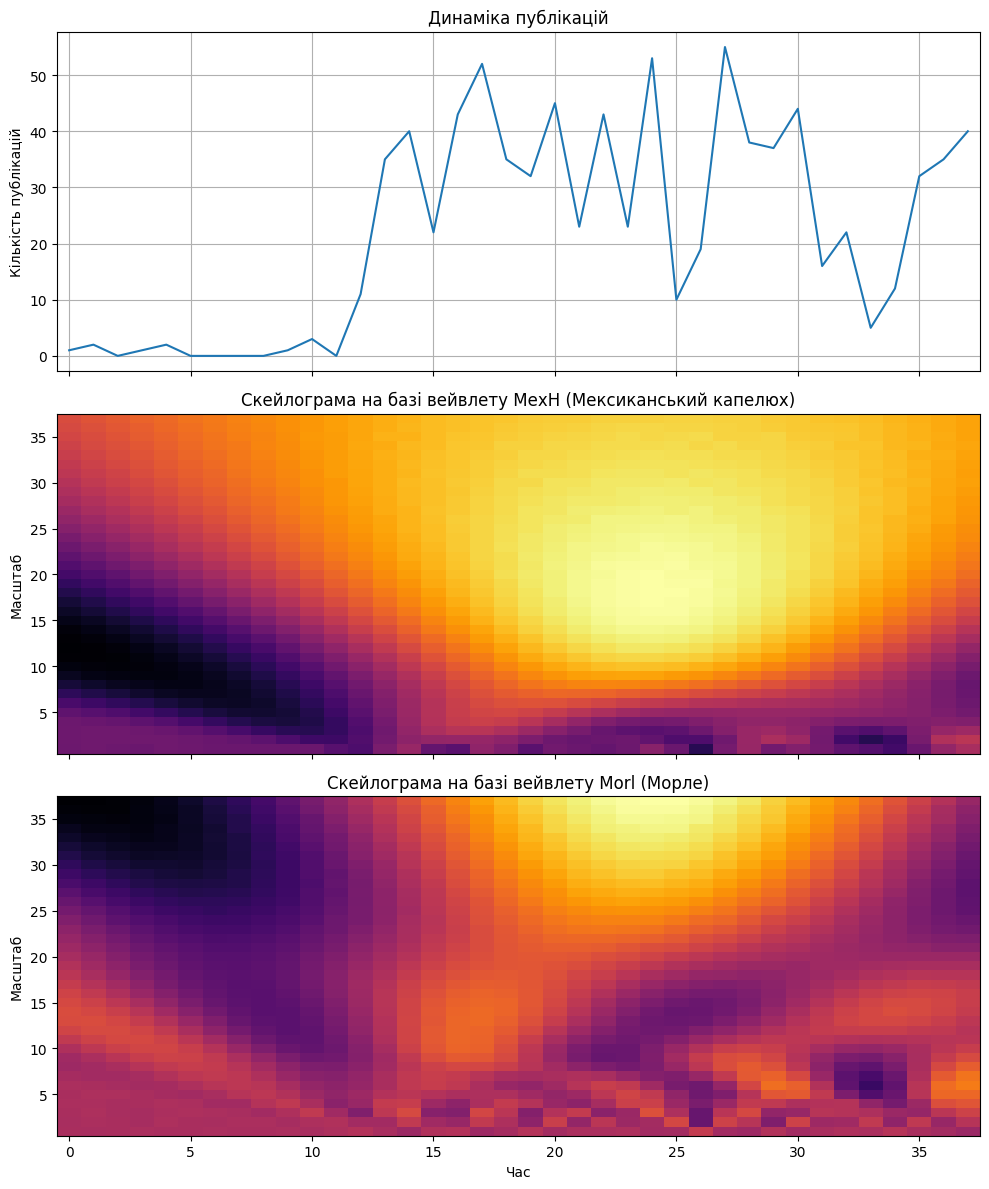

In [4]:
!pip install PyWavelets -q

import matplotlib.pyplot as plt
import pywt
import numpy as np

fs = 100

x = [1, 2, 0, 1, 2, 0, 0, 0, 0, 1, 3, 0, 11, 35, 40, 22, 43, 52, 35, 32,
     45, 23, 43, 23, 53, 10, 19, 55, 38, 37, 44, 16, 22, 5, 12, 32, 35, 40]
N = len(x)
t = range(N)
scales = np.arange(1, N)

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(10, 12))

ax1.plot(t, x)
ax1.grid(True)
ax1.set_ylabel("Кількість публікацій")
ax1.set_title("Динаміка публікацій")

cwtmatr_mexh, freqs_mexh = pywt.cwt(x, scales, "mexh", fs)
ax2.pcolormesh(t, scales, cwtmatr_mexh, cmap="inferno", shading='auto')
ax2.set_ylabel("Масштаб")
ax2.set_title("Скейлограма на базі вейвлету МехН (Мексиканський капелюх)")

cwtmatr_morl, freqs_morl = pywt.cwt(x, scales, "morl", fs)
ax3.pcolormesh(t, scales, cwtmatr_morl, cmap="inferno", shading='auto')
ax3.set_ylabel("Масштаб")
ax3.set_xlabel("Час")
ax3.set_title("Скейлограма на базі вейвлету Morl (Морле)")

plt.tight_layout()
plt.show()

### Висновки: Дослідження різниці вейвлет-скейлограм
* **Мексиканський капелюх (`mexh`)**: Конструюється на основі другої похідної функції Гауса. Має найкращі показники локалізації у часовій області. На графіку це виглядає як звужені вертикальні конуси, що ідеально підходять для точного виявлення різких поодиноких сплесків.
* **Вейвлет Морле (`morl`)**: Містить більше осциляцій. Гірше фіксує точний час поодинокого стрибка, проте набагато краще виділяє плавні періодичні зміни, загальну тривалість тренду та його інтенсивність.